<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/multi_agent_security_cascade_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Multi-Agent Network Topology Generator]
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Multi-Agent Security Cascade Simulator Initialized on: {device}")

class MultiAgentNetworkSimulator:
    """
    Simulates a directed topology of interacting AI agents:
    Node 0: User/Ingress Gateway
    Node 1: Planner Agent
    Node 2: Retrieval Agent (Infection Origin)
    Node 3: Code Execution Agent
    Node 4: Audit & Logging Agent
    """
    def __init__(self, num_agents: int = 10, connectivity_prob: float = 0.35):
        self.num_agents = num_agents
        self.graph = nx.erdos_renyi_graph(n=num_agents, p=connectivity_prob, directed=True, seed=42)
        # Ensure directed execution flow
        for i in range(num_agents - 1):
            if not self.graph.has_edge(i, i + 1):
                self.graph.add_edge(i, i + 1)

    def get_topology_adj(self) -> torch.Tensor:
        adj = nx.to_numpy_array(self.graph)
        return torch.tensor(adj, dtype=torch.float32, device=device)

sim_network = MultiAgentNetworkSimulator(num_agents=10)
adj_matrix = sim_network.get_topology_adj()

print(f"Multi-Agent System Topology Initialized:")
print(f"  * Total Interacting Agents: {sim_network.num_agents}")
print(f"  * Total Interaction Channels (Edges): {sim_network.graph.number_of_edges()}")

Multi-Agent Security Cascade Simulator Initialized on: cuda
Multi-Agent System Topology Initialized:
  * Total Interacting Agents: 10
  * Total Interaction Channels (Edges): 45


In [2]:
# [CELL 2 - Multi-Agent Prompt Injection Cascade & Contagion Engine]

class AgentNode(nn.Module):
    """
    Simulates an individual agent node processing incoming multi-agent payloads.
    Tracks state: 0.0 (Clean/Uncompromised), 1.0 (Infected/Jailbroken).
    """
    def __init__(self, agent_id: int):
        super().__init__()
        self.agent_id = agent_id
        self.is_infected = False

class MultiAgentSecurityEnvironment:
    def __init__(self, network: MultiAgentNetworkSimulator, infection_transmissibility: float = 0.85):
        self.network = network
        self.transmissibility = infection_transmissibility

    def run_cascade_simulation(self, patient_zero_id: int = 2, num_steps: int = 6, defense_enabled: bool = False, defense_efficiency: float = 0.70) -> list[float]:
        num_agents = self.network.num_agents
        infected = torch.zeros(num_agents, device=device)
        infected[patient_zero_id] = 1.0 # Patient Zero (e.g., poisoned retrieval tool)

        infection_history = [infected.sum().item() / num_agents * 100.0]
        adj = self.network.get_topology_adj()

        for step in range(num_steps):
            # Compute incoming infection pressure from connected infected neighbors
            incoming_pressure = torch.matmul(adj.T, infected)

            # Propagation probability
            prob_infection = 1.0 - torch.exp(-self.transmissibility * incoming_pressure)

            if defense_enabled:
                # Defensive interaction gate filters malicious payload propagation
                prob_infection = prob_infection * (1.0 - defense_efficiency)

            new_infections = (torch.rand(num_agents, device=device) < prob_infection).float()
            infected = torch.clamp(infected + new_infections, 0.0, 1.0)
            infection_history.append(infected.sum().item() / num_agents * 100.0)

        return infection_history

env = MultiAgentSecurityEnvironment(sim_network)
print("Multi-Agent Security & Cascade Contagion Environment Initialized.")

Multi-Agent Security & Cascade Contagion Environment Initialized.


In [3]:
# [CELL 3 - Cascade Propagation & Security-Utility Benchmark Suite]

def run_benchmark_suite(env: MultiAgentSecurityEnvironment, trials: int = 100) -> tuple[np.ndarray, np.ndarray]:
    undefended_runs = []
    defended_runs = []

    for _ in range(trials):
        # Random initial patient zero node
        p_zero = random.randint(0, env.network.num_agents - 1)

        hist_undef = env.run_cascade_simulation(patient_zero_id=p_zero, defense_enabled=False)
        hist_def = env.run_cascade_simulation(patient_zero_id=p_zero, defense_enabled=True, defense_efficiency=0.75)

        undefended_runs.append(hist_undef)
        defended_runs.append(hist_def)

    mean_undefended = np.mean(undefended_runs, axis=0)
    mean_defended = np.mean(defended_runs, axis=0)

    return mean_undefended, mean_defended

mean_undef, mean_def = run_benchmark_suite(env, trials=100)

print("\n--- Multi-Agent Security Cascade Benchmark Summary ---")
print(f"  * Final Undefended System Infection Rate: {mean_undef[-1]:.1f}%")
print(f"  * Final Defended System Infection Rate (Defensive Gate): {mean_def[-1]:.1f}%")
print(f"  * Infection Spread Reduction: {mean_undef[-1] - mean_def[-1]:.1f}% Percentage Points")


--- Multi-Agent Security Cascade Benchmark Summary ---
  * Final Undefended System Infection Rate: 100.0%
  * Final Defended System Infection Rate (Defensive Gate): 59.2%
  * Infection Spread Reduction: 40.8% Percentage Points


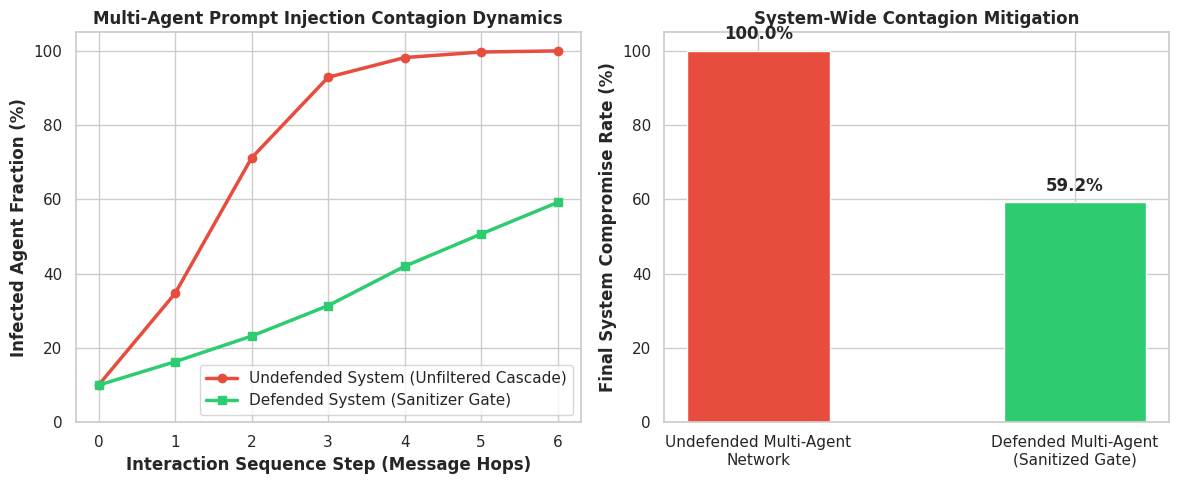

Multi-agent security visualization saved successfully as multi_agent_security_cascade_benchmarks.png.


In [4]:
# [CELL 4 - Multi-Panel Visualization of Multi-Agent Cascade & Defense Mitigation]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Cascade Infection Rate Over Interaction Hops
hops = list(range(len(mean_undef)))
ax1.plot(hops, mean_undef, marker='o', color='#e74c3c', linewidth=2.5, label='Undefended System (Unfiltered Cascade)')
ax1.plot(hops, mean_def, marker='s', color='#2ecc71', linewidth=2.5, label='Defended System (Sanitizer Gate)')

ax1.set_title("Multi-Agent Prompt Injection Contagion Dynamics", fontweight='bold')
ax1.set_xlabel("Interaction Sequence Step (Message Hops)", fontweight='bold')
ax1.set_ylabel("Infected Agent Fraction (%)", fontweight='bold')
ax1.set_ylim(0, 105)
ax1.legend(loc='lower right', frameon=True)

# Plot 2: Final Infection Rate Comparison
systems = ['Undefended Multi-Agent\nNetwork', 'Defended Multi-Agent\n(Sanitized Gate)']
final_rates = [mean_undef[-1], mean_def[-1]]

bars = ax2.bar(systems, final_rates, color=['#e74c3c', '#2ecc71'], width=0.45)
ax2.set_title("System-Wide Contagion Mitigation", fontweight='bold')
ax2.set_ylabel("Final System Compromise Rate (%)", fontweight='bold')
ax2.set_ylim(0, 105)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("multi_agent_security_cascade_benchmarks.png", dpi=300)
plt.show()

print("Multi-agent security visualization saved successfully as multi_agent_security_cascade_benchmarks.png.")